In [1]:
#!/usr/bin/env python3
import pymongo
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import os

# ---- CONFIG ----
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
EXPORT_DIR = "figures_tables/chunk_analysis_output"
os.makedirs(EXPORT_DIR, exist_ok=True)

# ---- Connect to MongoDB ----
client = pymongo.MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

# ---- Aggregation Query ----
print("🔄 Fetching chunk validation data from MongoDB...")
cursor = collection.find({
    "validation_info.checks.chunk_validation.metrics": {"$exists": True}
}, {
    "_id": 1,
    "validation_info.checks.chunk_validation.status": 1,
    "validation_info.checks.chunk_validation.metrics": 1
})

# ---- Flatten and Load into DataFrame ----
docs = []
for doc in tqdm(cursor, desc="📦 Loading documents"):
    _id = doc["_id"]
    chunk_info = doc["validation_info"]["checks"]["chunk_validation"]
    metrics = chunk_info["metrics"]
    token_stats = metrics.get("token_length_distribution", {})

    docs.append({
        "doc_id": _id,
        "chunk_status": chunk_info.get("status", "unknown"),
        "paragraph_count": metrics.get("paragraph_count", 0),
        "chunks_too_long": metrics.get("chunks_too_long", 0),
        "chunks_too_short": metrics.get("chunks_too_short", 0),
        "empty_chunks": metrics.get("empty_chunks", 0),
        "missing_embeddings": metrics.get("missing_embeddings", 0),
        "invalid_embedding_vectors": metrics.get("invalid_embedding_vectors", 0),
        "chunk_token_min": token_stats.get("min", 0),
        "chunk_token_Q1": token_stats.get("Q1", 0),
        "chunk_token_Q2": token_stats.get("Q2", 0),
        "chunk_token_Q3": token_stats.get("Q3", 0),
        "chunk_token_max": token_stats.get("max", 0),
        "chunk_token_mean": token_stats.get("mean", 0),
    })

df = pd.DataFrame(docs)
print(f"✅ Loaded {len(df)} documents")

# ---- Save Raw CSV ----
df.to_csv(os.path.join(EXPORT_DIR, "chunk_validation_summary.csv"), index=False)
print("📁 Saved summary CSV.")


🔄 Fetching chunk validation data from MongoDB...


📦 Loading documents: 582683it [00:09, 60521.93it/s]


✅ Loaded 582683 documents
📁 Saved summary CSV.


In [2]:
# Identify documents with all zero token stats
zero_stat_docs = df[
    (df["chunk_token_min"] == 0) &
    (df["chunk_token_Q1"] == 0) &
    (df["chunk_token_Q2"] == 0) &
    (df["chunk_token_Q3"] == 0) &
    (df["chunk_token_max"] == 0)
]

# Save to CSV log for audit trail
zero_stat_path = os.path.join(EXPORT_DIR, "excluded_zero_token_docs.csv")
zero_stat_docs.to_csv(zero_stat_path, index=False)
print(f"📝 Logged {len(zero_stat_docs)} excluded documents to: {zero_stat_path}")

# Filter them out for all future analysis
valid_df = df[~df.index.isin(zero_stat_docs.index)]
print(f"✅ Remaining valid documents: {len(valid_df)}")


📝 Logged 0 excluded documents to: figures_tables/chunk_analysis_output/excluded_zero_token_docs.csv
✅ Remaining valid documents: 582683


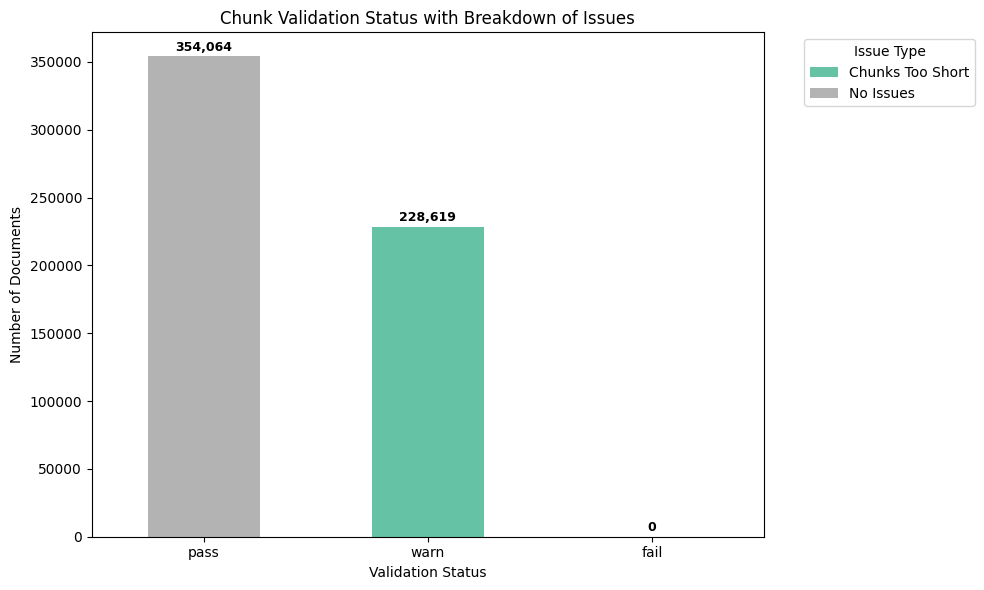

In [3]:
# Prepare counts for all statuses
status_counts = valid_df["chunk_status"].value_counts().reset_index()
status_counts.columns = ["chunk_status", "doc_count"]

# Compute issue breakdown for warn/fail
non_pass_df = valid_df[valid_df["chunk_status"] != "pass"]
issue_cols = [
    "chunks_too_long",
    "chunks_too_short",
    "empty_chunks",
    "missing_embeddings",
    "invalid_embedding_vectors"
]

# Melt to long format
melted_issues = non_pass_df.melt(
    id_vars=["doc_id", "chunk_status"],
    value_vars=issue_cols,
    var_name="issue_type",
    value_name="count"
)
melted_issues = melted_issues[melted_issues["count"] > 0]

# Count documents by issue and status
issue_summary = melted_issues.groupby(["chunk_status", "issue_type"]).size().reset_index(name="doc_count")

# Optional: rename for readability
issue_summary["issue_type"] = issue_summary["issue_type"].replace({
    "chunks_too_short": "Chunks Too Short",
    "chunks_too_long": "Chunks Too Long",
    "empty_chunks": "Empty Chunks",
    "missing_embeddings": "Missing Embeddings",
    "invalid_embedding_vectors": "Invalid Embeddings"
})

# Append pass row for consistency
pass_row = pd.DataFrame([{
    "chunk_status": "pass",
    "issue_type": "No Issues",
    "doc_count": valid_df["chunk_status"].value_counts().get("pass", 0)
}])
combined_summary = pd.concat([issue_summary, pass_row], ignore_index=True)

# Pivot for stacked bar plot
pivot_df = combined_summary.pivot(index="chunk_status", columns="issue_type", values="doc_count").fillna(0)

# Sort chunk_status for consistent display
pivot_df = pivot_df.reindex(["pass", "warn", "fail"], fill_value=0)

# Plot stacked bar chart and capture axes
ax = pivot_df.plot(kind="bar", stacked=True, colormap="Set2", figsize=(10, 6))
plt.title("Chunk Validation Status with Breakdown of Issues")
plt.xlabel("Validation Status")
plt.ylabel("Number of Documents")
plt.xticks(rotation=0)
plt.legend(title="Issue Type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

# Add total document count on top of each stacked bar
for i, bar_group in enumerate(ax.containers[-1]):
    # Sum the height from all stacked layers at position i
    total_height = sum([bar[i].get_height() for bar in ax.containers])
    x_pos = bar_group.get_x() + bar_group.get_width() / 2
    ax.text(x_pos, total_height + 2000, f"{int(total_height):,}", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Save and show
plt.savefig(os.path.join(EXPORT_DIR, "combined_status_issue_breakdown.png"))
plt.show()


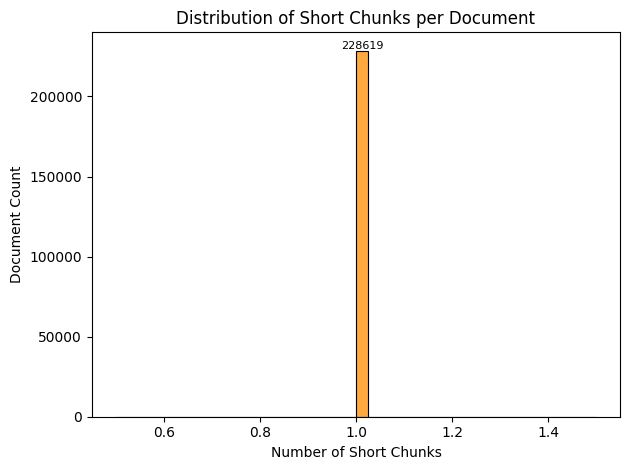

<Figure size 640x480 with 0 Axes>

In [4]:
# Filter only documents with at least one short chunk
docs_with_short_chunks = valid_df[valid_df["chunks_too_short"] > 0]

# Plot histogram and store the artist to access bar containers
ax = sns.histplot(
    data=docs_with_short_chunks,
    x="chunks_too_short",
    bins=40,
    color="darkorange"
)

# Add count labels on top of bars
for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        x = patch.get_x() + patch.get_width() / 2
        ax.text(x, height + 10, f"{int(height)}", ha="center", va="bottom", fontsize=8)

# Finalize plot
plt.title("Distribution of Short Chunks per Document")
plt.xlabel("Number of Short Chunks")
plt.ylabel("Document Count")
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "short_chunks_per_document_hist.png"))
plt.show()
plt.clf()


🔍 Collecting short chunks: 582683it [02:58, 3266.41it/s]


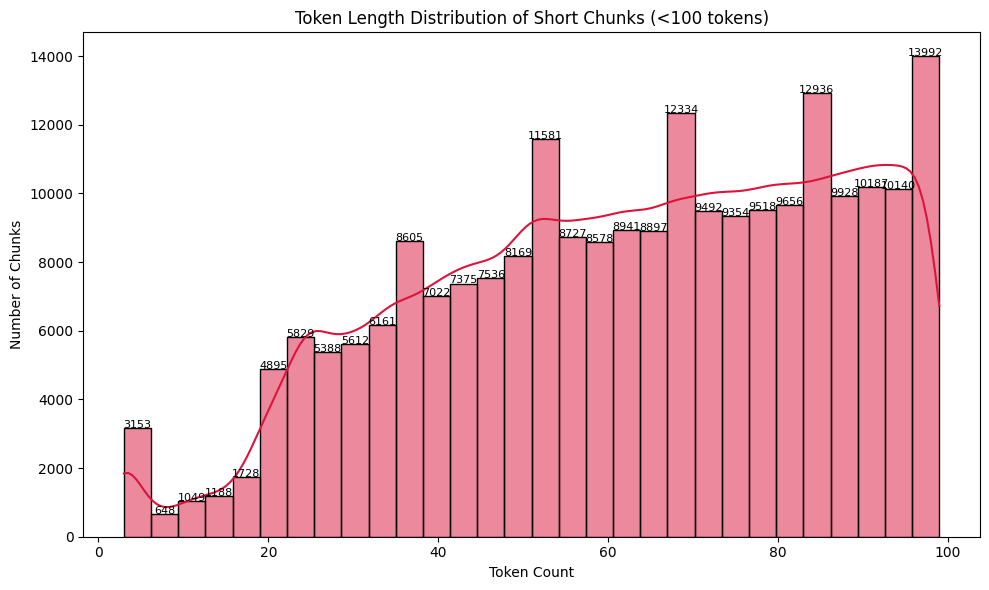

<Figure size 640x480 with 0 Axes>

In [5]:
from tqdm import tqdm
import pymongo
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Setup
short_chunk_lengths = []
min_token_threshold = 100  # as per your validation config
EXPORT_DIR = "figures_tables/chunk_analysis_output"
os.makedirs(EXPORT_DIR, exist_ok=True)

# Mongo connection
client = pymongo.MongoClient("mongodb://localhost:27017/")
collection = client["validation_db"]["document_validations"]

# Query only docs with chunk_validation.paragraphs
cursor = collection.find({
    "validation_info.checks.chunk_validation.paragraphs": {"$exists": True}
}, {
    "_id": 1,
    "validation_info.checks.chunk_validation.paragraphs": 1
})

# Extract short chunk lengths
for doc in tqdm(cursor, desc="🔍 Collecting short chunks"):
    paragraphs = doc.get("validation_info", {}).get("checks", {}).get("chunk_validation", {}).get("paragraphs", {})
    for para in paragraphs.values():
        token_len = para.get("token_length", 0)
        if token_len < min_token_threshold:
            short_chunk_lengths.append(token_len)

# Convert to DataFrame
short_df = pd.Series(short_chunk_lengths, name="Short Chunk Length")

# Save raw data (optional)
short_df.to_csv(os.path.join(EXPORT_DIR, "short_chunk_lengths.csv"), index=False)

# Plot
plt.figure(figsize=(10, 6))
ax = sns.histplot(short_df, bins=30, color="crimson", kde=True)
plt.title("Token Length Distribution of Short Chunks (<100 tokens)")
plt.xlabel("Token Count")
plt.ylabel("Number of Chunks")

# Add counts on bars
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        x = bar.get_x() + bar.get_width() / 2
        ax.text(x, height + 2, f"{int(height)}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "short_chunk_token_length_distribution.png"))
plt.show()
plt.clf()


📚 Analyzing short chunk positions: 582683it [03:24, 2843.32it/s]
/tmp/ipykernel_1691154/1728821363.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=zone_summary.index, y=zone_summary.values, palette="Set2")


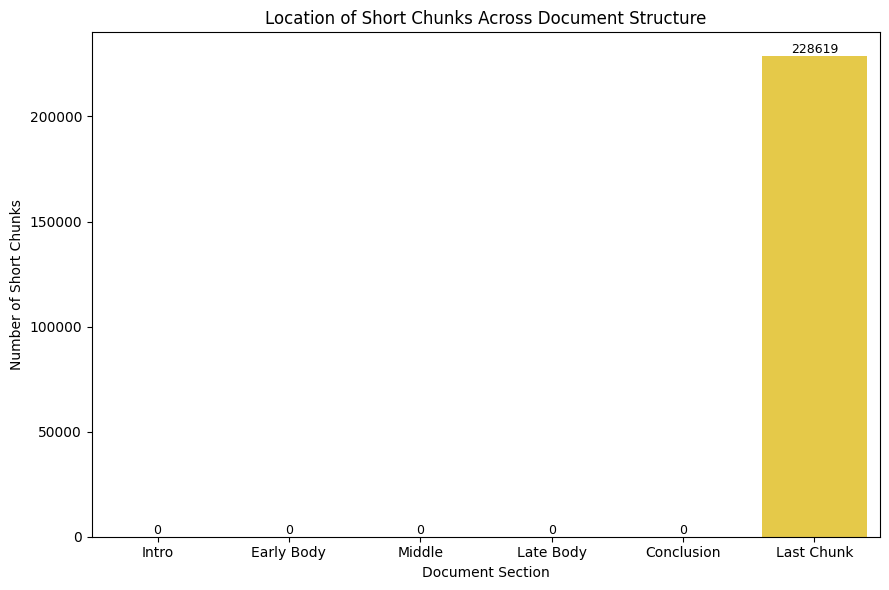

<Figure size 640x480 with 0 Axes>

In [6]:
import pymongo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import re
import os

# Mongo connection
client = pymongo.MongoClient("mongodb://localhost:27017/")
collection = client["validation_db"]["document_validations"]

EXPORT_DIR = "figures_tables/chunk_analysis_output"
os.makedirs(EXPORT_DIR, exist_ok=True)

# Settings
min_token_threshold = 100
zone_bins = [0, 0.2, 0.4, 0.6, 0.8, 1.01]
zone_labels = ["Intro", "Early Body", "Middle", "Late Body", "Conclusion"]
all_labels = zone_labels + ["Last Chunk"]  # add final category

# Query documents with paragraph token lengths
cursor = collection.find({
    "validation_info.checks.chunk_validation.paragraphs": {"$exists": True}
}, {
    "_id": 1,
    "validation_info.checks.chunk_validation.paragraphs": 1
})

# Collect short chunk locations
short_chunk_zones = []

for doc in tqdm(cursor, desc="📚 Analyzing short chunk positions"):
    paragraphs = doc.get("validation_info", {}).get("checks", {}).get("chunk_validation", {}).get("paragraphs", {})
    if not paragraphs:
        continue

    # Extract paragraph indices
    para_indices = []
    para_map = {}
    for pid in paragraphs:
        match = re.search(r"[Pp](\d+)$", pid)
        if match:
            idx = int(match.group(1))
            para_indices.append(idx)
            para_map[idx] = pid

    if not para_indices:
        continue

    max_idx = max(para_indices)

    for idx in para_indices:
        pid = para_map[idx]
        pdata = paragraphs[pid]
        token_len = pdata.get("token_length", 0)

        if token_len >= min_token_threshold:
            continue

        # Assign to "Last Chunk" if it's the last paragraph
        if idx == max_idx:
            short_chunk_zones.append("Last Chunk")
        else:
            norm_pos = idx / max_idx if max_idx > 0 else 0
            for i in range(len(zone_bins) - 1):
                if zone_bins[i] <= norm_pos < zone_bins[i + 1]:
                    short_chunk_zones.append(zone_labels[i])
                    break

# Convert to DataFrame
zone_df = pd.Series(short_chunk_zones, name="zone")
zone_summary = zone_df.value_counts().reindex(all_labels, fill_value=0)

# Save raw data
zone_df.to_csv(os.path.join(EXPORT_DIR, "short_chunk_zones.csv"), index=False)

# Plot
plt.figure(figsize=(9, 6))
sns.barplot(x=zone_summary.index, y=zone_summary.values, palette="Set2")
plt.title("Location of Short Chunks Across Document Structure")
plt.xlabel("Document Section")
plt.ylabel("Number of Short Chunks")

# Add labels
for i, v in enumerate(zone_summary.values):
    plt.text(i, v + 2, str(v), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "short_chunk_zones_barplot.png"))
plt.show()
plt.clf()


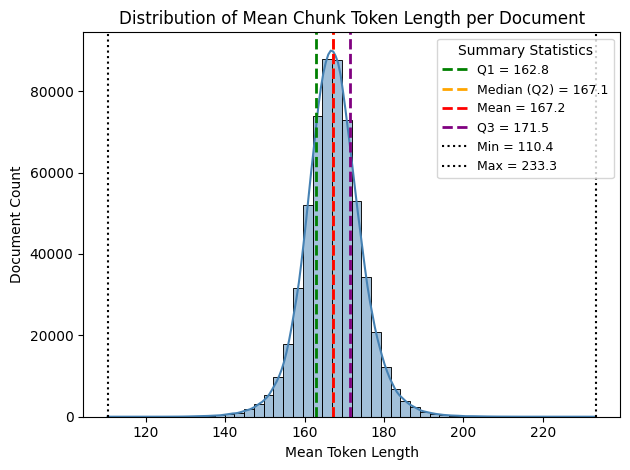

<Figure size 640x480 with 0 Axes>

In [7]:
# 2. Mean Token Length Histogram with min, max, and legend
import numpy as np

# Compute statistics
mean_val = valid_df["chunk_token_mean"].mean()
q1 = valid_df["chunk_token_mean"].quantile(0.25)
q2 = valid_df["chunk_token_mean"].quantile(0.50)
q3 = valid_df["chunk_token_mean"].quantile(0.75)
min_val = valid_df["chunk_token_mean"].min()
max_val = valid_df["chunk_token_mean"].max()

# Plot histogram and KDE
sns.histplot(valid_df["chunk_token_mean"], bins=50, kde=True, color="steelblue")
plt.title("Distribution of Mean Chunk Token Length per Document")
plt.xlabel("Mean Token Length")
plt.ylabel("Document Count")

# Add vertical lines for quartiles + mean
plt.axvline(q1, linestyle="--", color="green", linewidth=2, label=f"Q1 = {q1:.1f}")
plt.axvline(q2, linestyle="--", color="orange", linewidth=2, label=f"Median (Q2) = {q2:.1f}")
plt.axvline(mean_val, linestyle="--", color="red", linewidth=2, label=f"Mean = {mean_val:.1f}")
plt.axvline(q3, linestyle="--", color="purple", linewidth=2, label=f"Q3 = {q3:.1f}")

# Add vertical lines for min and max
plt.axvline(min_val, linestyle=":", color="black", linewidth=1.5, label=f"Min = {min_val:.1f}")
plt.axvline(max_val, linestyle=":", color="black", linewidth=1.5, label=f"Max = {max_val:.1f}")

# Add legend
plt.legend(title="Summary Statistics", loc="upper right", fontsize=9)
plt.tight_layout()

# Save and show
plt.savefig(os.path.join(EXPORT_DIR, "02_chunk_token_mean_hist_with_legend_min_max.png"))
plt.show()
plt.clf()


/tmp/ipykernel_1691154/1850924903.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


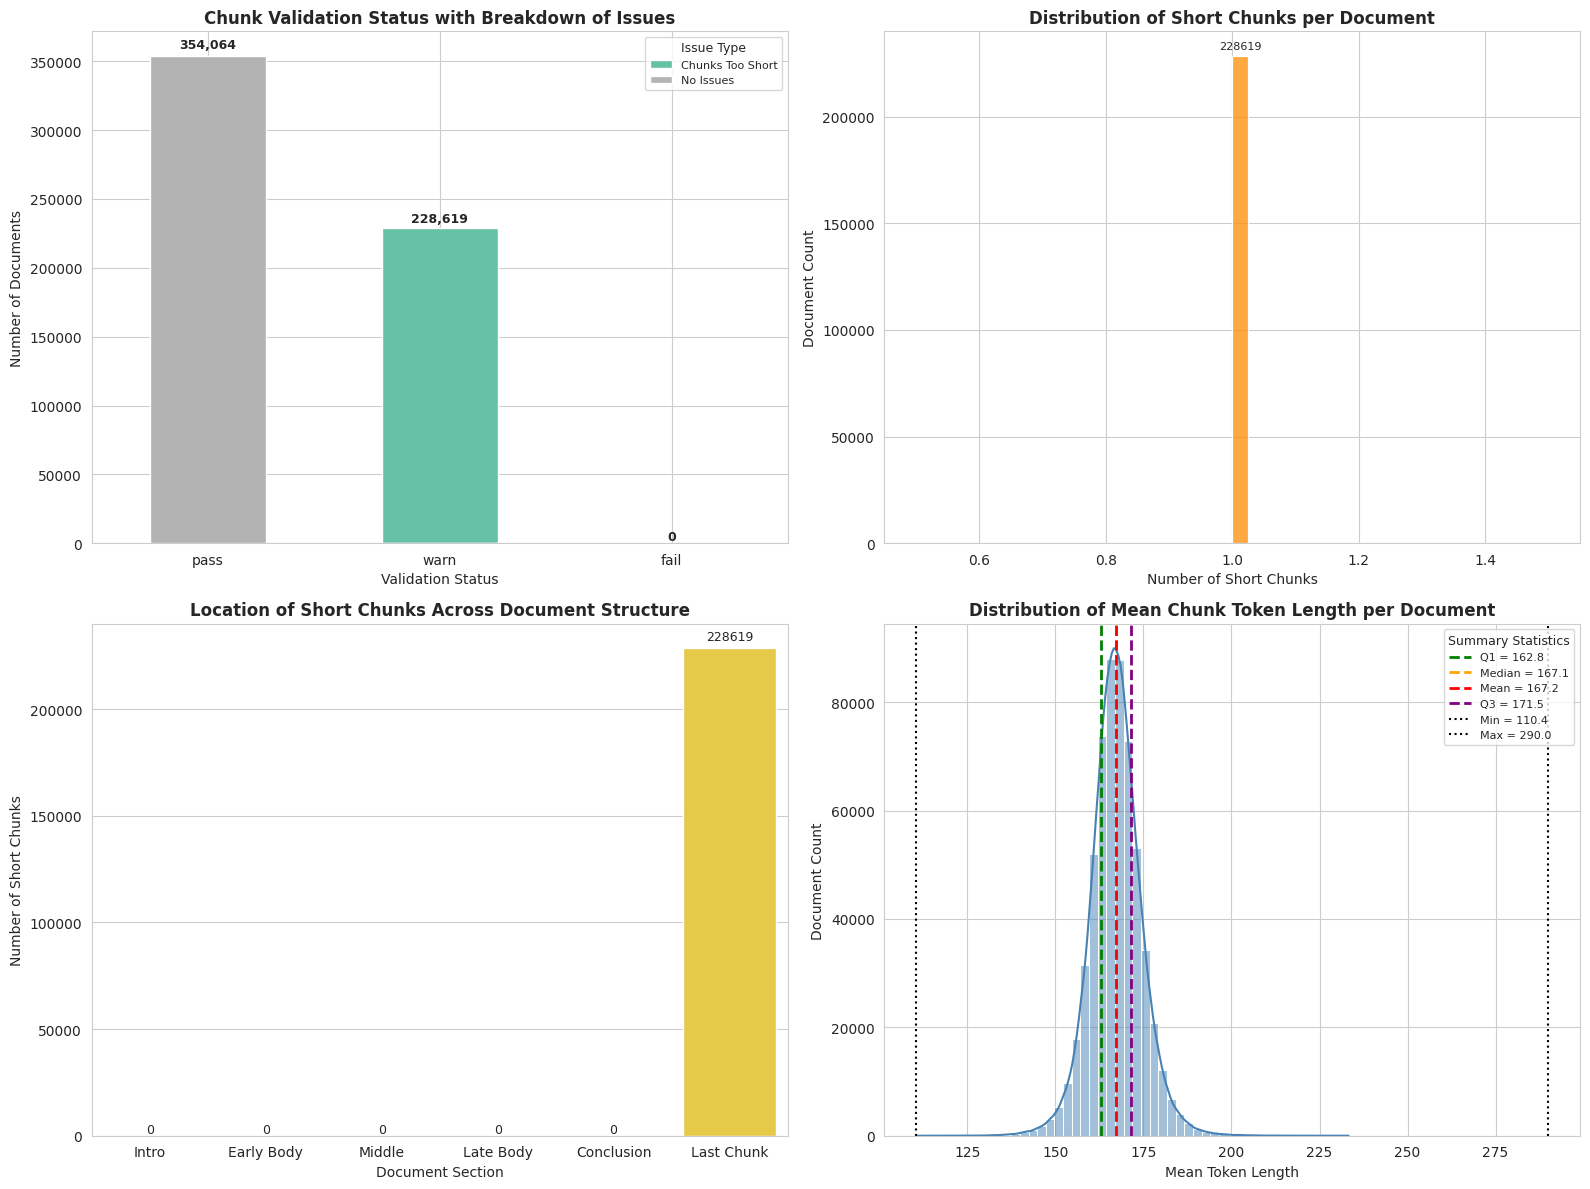

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")  # consistent seaborn style

# Create 2×2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(wspace=0.3, hspace=0.35)

# -----------------------------
# 1. Chunk Validation Status (stacked bar)
pivot_df.plot(
    kind="bar", stacked=True, colormap="Set2", ax=axes[0, 0], legend=False
)
axes[0, 0].set_title("Chunk Validation Status with Breakdown of Issues", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Validation Status", fontsize=10)
axes[0, 0].set_ylabel("Number of Documents", fontsize=10)
axes[0, 0].set_xticklabels(axes[0, 0].get_xticklabels(), rotation=0)

# Add total counts above bars
for i in range(len(pivot_df)):
    total_height = pivot_df.iloc[i].sum()
    axes[0, 0].text(i, total_height + total_height * 0.01,
                    f"{int(total_height):,}",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

# Add legend inside plot (upper right corner)
axes[0, 0].legend(
    title="Issue Type",
    loc="upper right",
    fontsize=8,
    title_fontsize=9,
    frameon=True
)

# -----------------------------
# 2. Distribution of Short Chunks per Document (histogram)
sns.histplot(
    data=docs_with_short_chunks,
    x="chunks_too_short",
    bins=40,
    color="darkorange",
    ax=axes[0, 1]
)
for patch in axes[0, 1].patches:
    height = patch.get_height()
    if height > 0:
        x = patch.get_x() + patch.get_width() / 2
        axes[0, 1].text(x, height + height * 0.01,
                        f"{int(height)}",
                        ha="center", va="bottom", fontsize=8)
axes[0, 1].set_title("Distribution of Short Chunks per Document", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Number of Short Chunks", fontsize=10)
axes[0, 1].set_ylabel("Document Count", fontsize=10)

# -----------------------------
# 3. Location of Short Chunks Across Document Structure (barplot)
sns.barplot(
    x=zone_summary.index,
    y=zone_summary.values,
    palette="Set2",
    ax=axes[1, 0]
)
for i, v in enumerate(zone_summary.values):
    axes[1, 0].text(i, v + v * 0.01 if v > 0 else 1,
                    str(v), ha='center', va='bottom', fontsize=9)
axes[1, 0].set_title("Location of Short Chunks Across Document Structure", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Document Section", fontsize=10)
axes[1, 0].set_ylabel("Number of Short Chunks", fontsize=10)

# -----------------------------
# 4. Mean Token Length Histogram
sns.histplot(valid_df["chunk_token_mean"], bins=50, kde=True, color="steelblue", ax=axes[1, 1])
axes[1, 1].set_title("Distribution of Mean Chunk Token Length per Document", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Mean Token Length", fontsize=10)
axes[1, 1].set_ylabel("Document Count", fontsize=10)

# Add vertical lines for quartiles, mean, min, max
axes[1, 1].axvline(q1, linestyle="--", color="green", linewidth=2, label=f"Q1 = {q1:.1f}")
axes[1, 1].axvline(q2, linestyle="--", color="orange", linewidth=2, label=f"Median = {q2:.1f}")
axes[1, 1].axvline(mean_val, linestyle="--", color="red", linewidth=2, label=f"Mean = {mean_val:.1f}")
axes[1, 1].axvline(q3, linestyle="--", color="purple", linewidth=2, label=f"Q3 = {q3:.1f}")
axes[1, 1].axvline(min_val, linestyle=":", color="black", linewidth=1.5, label=f"Min = {min_val:.1f}")
axes[1, 1].axvline(max_val, linestyle=":", color="black", linewidth=1.5, label=f"Max = {max_val:.1f}")
axes[1, 1].legend(title="Summary Statistics", loc="upper right", fontsize=8, title_fontsize=9, frameon=True)

# -----------------------------
# Save combined figure
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, "combined_all_plots_consistent_style.png"), dpi=300)
plt.show()


/tmp/ipykernel_1691154/1896518478.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Statistic", y="Token Count", data=melted, palette="pastel")


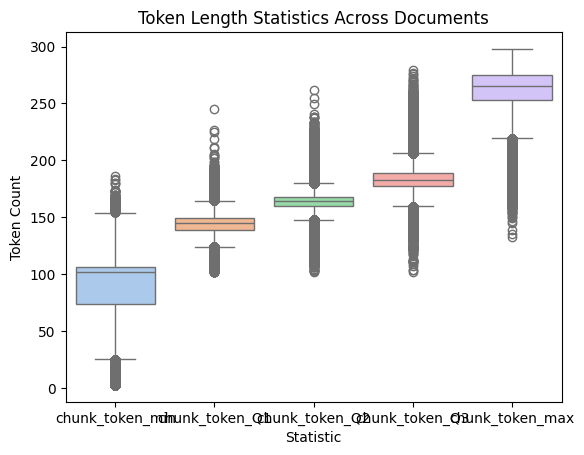

<Figure size 640x480 with 0 Axes>

In [8]:
# 3. Token Length Distribution (Boxplot)
melted = valid_df.melt(value_vars=[
    "chunk_token_min", "chunk_token_Q1", "chunk_token_Q2",
    "chunk_token_Q3", "chunk_token_max"
], var_name="Statistic", value_name="Token Count")
sns.boxplot(x="Statistic", y="Token Count", data=melted, palette="pastel")
plt.title("Token Length Statistics Across Documents")
plt.savefig(os.path.join(EXPORT_DIR, "03_token_length_boxplot.png"))
plt.show()
plt.clf()


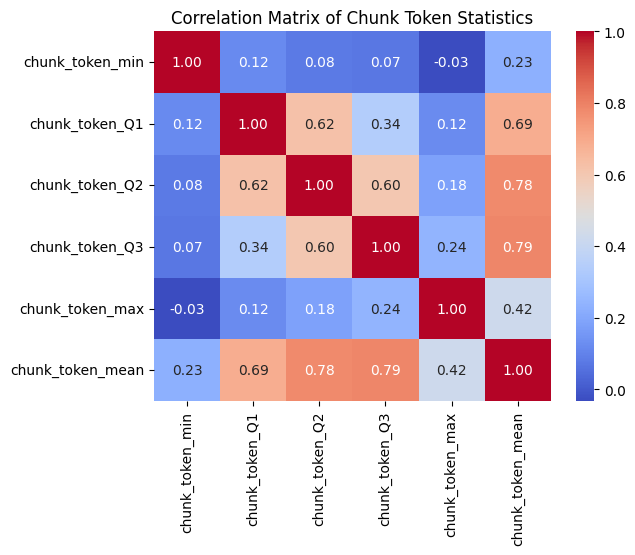

<Figure size 640x480 with 0 Axes>

In [9]:
# 4. Correlation Heatmap of Token Stats
token_cols = ["chunk_token_min", "chunk_token_Q1", "chunk_token_Q2", "chunk_token_Q3", "chunk_token_max", "chunk_token_mean"]
corr = df[token_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Chunk Token Statistics")
plt.savefig(os.path.join(EXPORT_DIR, "04_token_stats_correlation.png"))
plt.show()
plt.clf()

In [10]:
# ---- BASIC METRICS FOR REPORTING ----
total_chunks = df["paragraph_count"].sum()
print(f"🧮 Total number of chunks: {total_chunks:,}")

mean_chunk_len = df["chunk_token_mean"].mean()
std_chunk_len = df["chunk_token_mean"].std()
print(f"📏 Mean chunk length: {mean_chunk_len:.2f} tokens")
print(f"📐 Std dev of chunk length: {std_chunk_len:.2f} tokens")

🧮 Total number of chunks: 28,826,312
📏 Mean chunk length: 167.21 tokens
📐 Std dev of chunk length: 7.30 tokens


In [11]:
# ---- CLEAN SUBSET METRICS ----
fully_clean = df.query("chunks_too_long == 0 and chunks_too_short == 0")
semi_clean = df.query("chunks_too_long == 0")

print(f"✅ Fully clean documents: {len(fully_clean)} ({len(fully_clean)/len(df)*100:.2f}%)")
print(f"🟡 Semi-clean (no overlong chunks): {len(semi_clean)} ({len(semi_clean)/len(df)*100:.2f}%)")

print("📊 All final publication-quality plots saved to:", EXPORT_DIR)


✅ Fully clean documents: 354064 (60.76%)
🟡 Semi-clean (no overlong chunks): 582683 (100.00%)
📊 All final publication-quality plots saved to: figures_tables/chunk_analysis_output


In [12]:
import pymongo
from tqdm import tqdm

# Connect to MongoDB
client = pymongo.MongoClient("mongodb://localhost:27017/")
collection = client["validation_db"]["document_validations"]

# Metrics to analyze
metrics_of_interest = [
    "empty_chunks",
    "missing_embeddings",
    "invalid_embedding_vectors"
]

# Initialize counters
totals = {metric: 0 for metric in metrics_of_interest}
docs_with_issues = {metric: 0 for metric in metrics_of_interest}

# Query only documents that have chunk validation metrics
cursor = collection.find(
    {"validation_info.checks.chunk_validation.metrics": {"$exists": True}},
    {
        "_id": 1,
        **{f"validation_info.checks.chunk_validation.metrics.{m}": 1 for m in metrics_of_interest}
    }
)

# Count
for doc in tqdm(cursor, desc="🔍 Scanning documents"):
    metrics = doc.get("validation_info", {}).get("checks", {}).get("chunk_validation", {}).get("metrics", {})
    
    for metric in metrics_of_interest:
        count = metrics.get(metric, 0)
        totals[metric] += count
        if count > 0:
            docs_with_issues[metric] += 1

# Report
print("\n📊 Summary of Chunk Validation Issues:")
for metric in metrics_of_interest:
    print(f"🔸 {metric}:")
    print(f"   ├─ Total occurrences: {totals[metric]}")
    print(f"   └─ Documents affected: {docs_with_issues[metric]}")


🔍 Scanning documents: 582683it [00:07, 75932.65it/s] 


📊 Summary of Chunk Validation Issues:
🔸 empty_chunks:
   ├─ Total occurrences: 0
   └─ Documents affected: 0
🔸 missing_embeddings:
   ├─ Total occurrences: 0
   └─ Documents affected: 0
🔸 invalid_embedding_vectors:
   ├─ Total occurrences: 0
   └─ Documents affected: 0


In [13]:
# ───────────────────────────────────────────────────────
# Setup
# ───────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
from pathlib import Path
from tqdm.notebook import tqdm

# Settings
EXPORT_DIR = Path("figures_tables/chunk_analysis_output")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Configurable filters
language_filter = "en"       # Set to None to disable filtering
non_valid_threshold = 200    # Flag paragraphs with ≥ this many non-valid chars

# Mongo connection
client = MongoClient("mongodb://localhost:27017/")
collection = client["validation_db"]["document_validations"]


In [14]:
from tqdm.auto import tqdm

char_rows = []

cursor = collection.find({
    "validation_info.checks.chunk_validation.paragraphs": {"$exists": True}
}, {
    "_id": 1,
    "validation_info.checks.chunk_validation.paragraphs": 1,
    "validation_info.checks.text_validation.metrics.language": 1,
    "validation_info.checks.text_validation.flags.language_mismatch_or_low_confidence": 1
})

for doc in tqdm(cursor, desc="🔍 Collecting paragraph stats"):
    lang = doc.get("validation_info", {}).get("checks", {}).get("text_validation", {}).get("metrics", {}).get("language", "unknown")
    mismatch = doc.get("validation_info", {}).get("checks", {}).get("text_validation", {}).get("flags", {}).get("language_mismatch_or_low_confidence", False)
    paragraphs = doc["validation_info"]["checks"]["chunk_validation"]["paragraphs"]

    for pid, pdata in paragraphs.items():
        cc = pdata.get("char_counts", {})
        row = {
            "doc_id": doc["_id"],
            "paragraph_id": pid,
            "language": lang,
            "mismatch_flag": mismatch,
            "valid": cc.get("valid", 0),
            "corrupted": cc.get("corrupted", 0),
            "control": cc.get("control", 0),
            "formatting": cc.get("formatting", 0),
            "unassigned": cc.get("unassigned", 0),
        }
        row["non_valid_total"] = row["corrupted"] + row["control"] + row["formatting"] + row["unassigned"]
        char_rows.append(row)

char_df = pd.DataFrame(char_rows)
char_df.to_csv(EXPORT_DIR / "char_counts_by_language.csv", index=False)
char_df.head()


/home/mahmoud/rag/myenv/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
🔍 Collecting paragraph stats: 582683it [08:35, 1130.04it/s]


,doc_id,paragraph_id,language,mismatch_flag,valid,corrupted,control,formatting,unassigned,non_valid_total
0,100036667,100036667P0,en,False,888,0,0,0,0,0
1,100036667,100036667P1,en,False,803,0,0,0,0,0
2,100036667,100036667P2,en,False,553,0,0,0,0,0
3,100036667,100036667P3,en,False,778,0,0,0,0,0
4,100036667,100036667P4,en,False,922,0,0,0,0,0


In [15]:
mean_vals = char_df[["valid", "corrupted", "control", "formatting", "unassigned"]].mean()




In [16]:
long_tail_df = char_df[(char_df["corrupted"] > 0) | (char_df["formatting"] > 0)].copy()
long_tail_df["corrupt_plus_formatting"] = long_tail_df["corrupted"] + long_tail_df["formatting"]




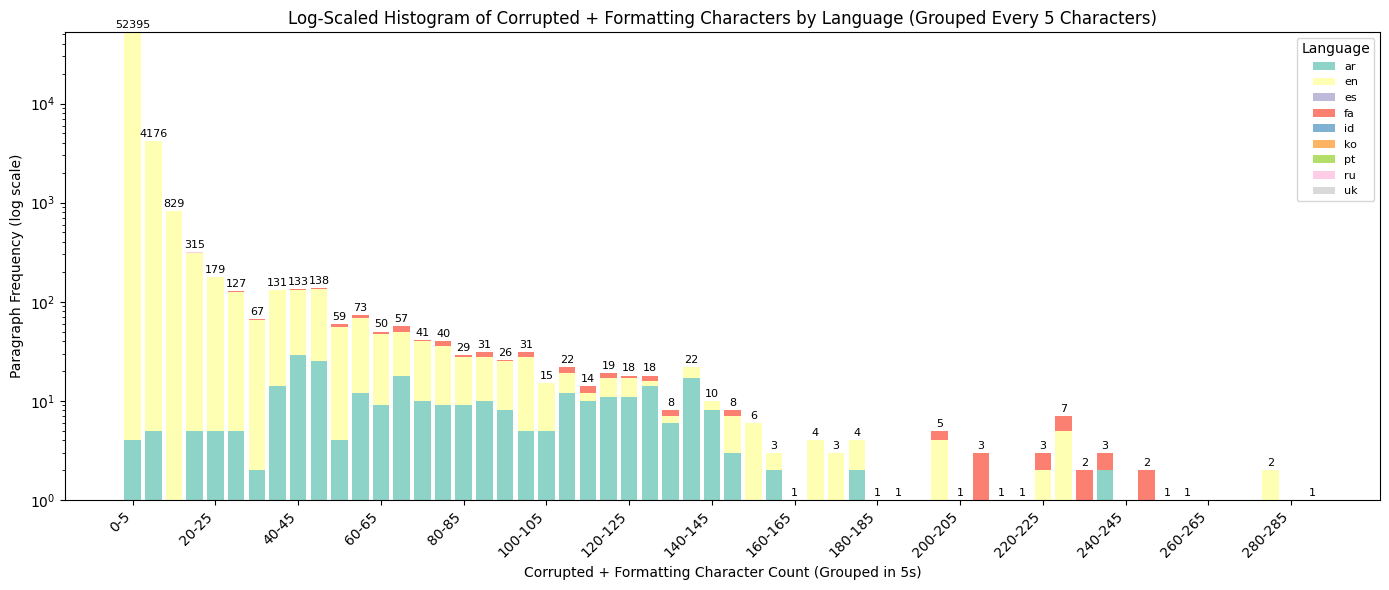

In [17]:
# 🧮 Create total corrupt+formatting column (if not already done)
long_tail_df["corrupt_plus_formatting"] = long_tail_df["corrupted"] + long_tail_df["formatting"]

# 📦 Define fixed-width bin edges: 0–5, 6–10, ..., up to max value
max_val = long_tail_df["corrupt_plus_formatting"].max()
bin_edges = list(range(0, int(np.ceil(max_val)) + 5, 5))  # step of 5

# 🪵 Bin the rows manually
long_tail_df["bin"] = pd.cut(long_tail_df["corrupt_plus_formatting"], bins=bin_edges, right=True)

# 📊 Group by bin and language
bin_lang_counts = long_tail_df.groupby(["bin", "language"]).size().unstack(fill_value=0)

# 🧱 Plot setup
x = np.arange(len(bin_lang_counts))
bin_labels = [f"{int(b.left)}-{int(b.right)}" for b in bin_lang_counts.index]
bottom = np.zeros(len(bin_lang_counts))
colors = sns.color_palette("Set3", n_colors=len(bin_lang_counts.columns))

plt.figure(figsize=(14, 6))

# 🎨 Draw stacked bars
for i, lang in enumerate(bin_lang_counts.columns):
    heights = bin_lang_counts[lang].values
    plt.bar(x, heights, bottom=bottom, label=lang, color=colors[i])
    bottom += heights

# ✍ Add total labels on top of each bar
for i, total in enumerate(bottom):
    if total > 0:
        plt.text(x[i], total * 1.05, f"{int(total)}", ha="center", va="bottom", fontsize=8)

# 📊 Final styling
plt.yscale("log")
plt.xticks(x[::4], bin_labels[::4], rotation=45, ha="right")
plt.xlabel("Corrupted + Formatting Character Count (Grouped in 5s)")
plt.ylabel("Paragraph Frequency (log scale)")
plt.title("Log-Scaled Histogram of Corrupted + Formatting Characters by Language (Grouped Every 5 Characters)")
plt.legend(title="Language", fontsize=8)
plt.tight_layout()
plt.savefig(EXPORT_DIR / "log_hist_corrupted_formatting_by_language_FIXEDBINS.png")
plt.show()


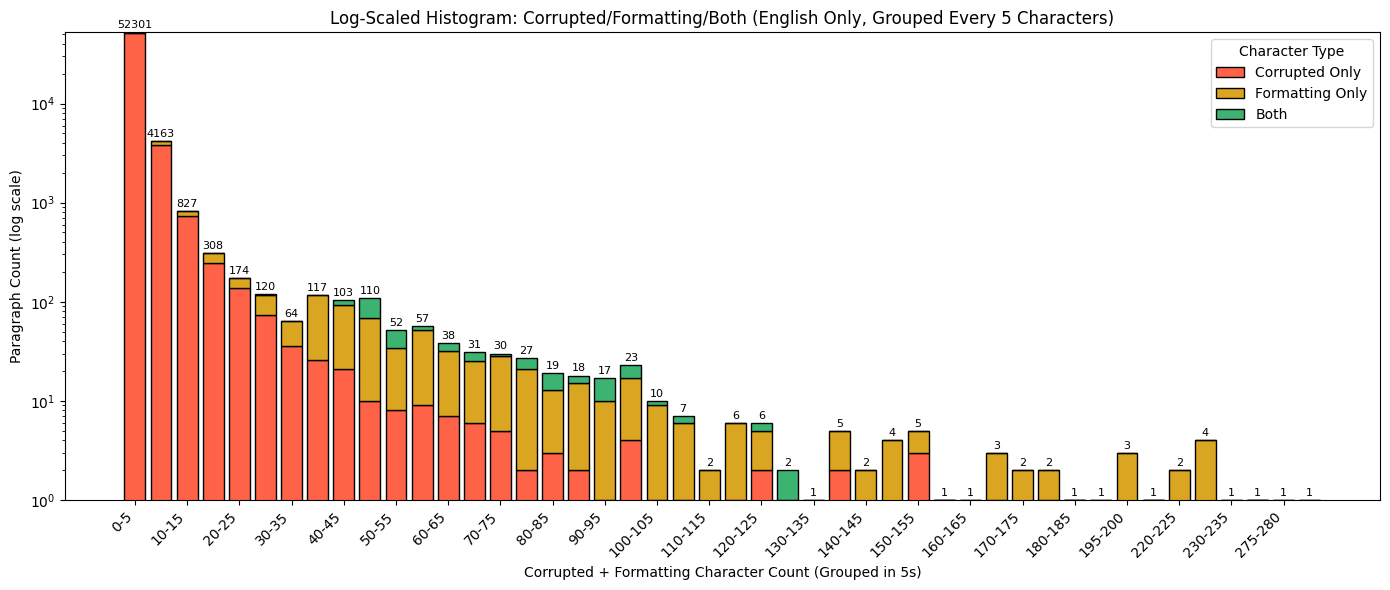

In [18]:
# 🧹 Filter to English and prepare total count
en_tail_df = long_tail_df[long_tail_df["language"] == language_filter].copy()
en_tail_df["corrupt_plus_formatting"] = en_tail_df["corrupted"] + en_tail_df["formatting"]

# 🏷 Categorize character type
def char_category(row):
    if row["corrupted"] > 0 and row["formatting"] > 0:
        return "Both"
    elif row["corrupted"] > 0:
        return "Corrupted Only"
    elif row["formatting"] > 0:
        return "Formatting Only"
    return "None"

en_tail_df["char_category"] = en_tail_df.apply(char_category, axis=1)
en_tail_df = en_tail_df[en_tail_df["char_category"] != "None"]

# 📦 Define fixed-width bin edges: 0–5, 6–10, ..., up to max value
max_val = en_tail_df["corrupt_plus_formatting"].max()
bin_edges = list(range(0, int(np.ceil(max_val)) + 5, 5))  # step of 5
en_tail_df["bin"] = pd.cut(en_tail_df["corrupt_plus_formatting"], bins=bin_edges, right=True)

# 📊 Count paragraphs per bin & category
cat_counts = en_tail_df.groupby(["bin", "char_category"]).size().unstack(fill_value=0)
cat_counts = cat_counts.loc[cat_counts.sum(axis=1) > 0]  # drop empty bins

# 🧱 Prepare plot
x = np.arange(len(cat_counts))
bin_labels = [f"{int(b.left)}-{int(b.right)}" for b in cat_counts.index]

colors = {
    "Corrupted Only": "tomato",
    "Formatting Only": "goldenrod",
    "Both": "mediumseagreen"
}
bottom = np.zeros(len(cat_counts))

plt.figure(figsize=(14, 6))

# 📦 Draw stacked bars
for category in ["Corrupted Only", "Formatting Only", "Both"]:
    heights = cat_counts.get(category, pd.Series(0, index=cat_counts.index)).values
    plt.bar(x, heights, bottom=bottom, label=category,
            color=colors[category], edgecolor="black")
    bottom += heights

# ✍ Annotate total on top
for i, total in enumerate(bottom):
    if total > 0:
        plt.text(x[i], total * 1.05, f"{int(total)}", ha="center", va="bottom", fontsize=8)

# 📊 Final touches
plt.yscale("log")
plt.xticks(x[::2], bin_labels[::2], rotation=45, ha="right")
plt.xlabel("Corrupted + Formatting Character Count (Grouped in 5s)")
plt.ylabel("Paragraph Count (log scale)")
plt.title("Log-Scaled Histogram: Corrupted/Formatting/Both (English Only, Grouped Every 5 Characters)")
plt.legend(title="Character Type")
plt.tight_layout()
plt.savefig(EXPORT_DIR / "log_hist_corrupted_formatting_3categories_EN_only_FIXEDBINS.png")
plt.show()


In [19]:
# Define the output path
output_path = EXPORT_DIR / "paragraphs_with_invalid_characters.csv"

# Filter for paragraphs with corrupted OR formatting characters
invalid_paragraphs_df = long_tail_df[
    (long_tail_df["corrupted"] > 0) | (long_tail_df["formatting"] > 0)
].copy()

# Optional: add total invalid character count
invalid_paragraphs_df["non_valid_total"] = (
    invalid_paragraphs_df["corrupted"] + invalid_paragraphs_df["formatting"]
)

# Select useful columns
cols_to_save = [
    "doc_id",
    "paragraph_id",
    "language",
    "corrupted",
    "formatting",
    "non_valid_total"
]
if "paragraph_name" in invalid_paragraphs_df.columns:
    cols_to_save.insert(2, "paragraph_name")

# Save to CSV
invalid_paragraphs_df[cols_to_save].to_csv(output_path, index=False)
print(f"✅ Saved {len(invalid_paragraphs_df)} paragraphs with invalid characters to:\n{output_path}")


✅ Saved 59137 paragraphs with invalid characters to:
figures_tables/chunk_analysis_output/paragraphs_with_invalid_characters.csv
